# Fase 2 · Desarrollo y modelado — Clasificador de PQRS en salud (chatbot WhatsApp incluyente)

**Objetivo:** construir, entrenar y evaluar el modelo que clasifica cada mensaje entrante del chatbot en **tipo de PQRS** (`Peticion`, `Queja`, `Reclamo`, `Sugerencia`, `Otro`) y en **intención fina** (17 intenciones), con un proceso experimental documentado.

| Entregable | Sección |
|---|---|
| Preprocesamiento: limpieza, transformación, ingeniería de características, partición train/val/test | 1 – 3 |
| ≥ 2 modelos (baseline + propuesto) con justificación | 4 |
| Entrenamiento y ajuste de hiperparámetros, bitácora de experimentos | 5 |
| Evaluación cuantitativa y comparación | 6 – 7 |
| Modelo transformer (BETO) — listo para ejecutar en Colab con GPU | 8 |

**Entradas** (generadas en la Fase 1): `pqrs_salud_sintetico.csv`, `glosario_salud_esp_way.csv`, y `pqrs_test_externo.csv` (68 mensajes **escritos a mano, fuera de las plantillas**, para medir generalización real).

In [1]:
import re, json, time, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, balanced_accuracy_score)
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 170)
SEED = 42
np.random.seed(SEED)

OUT = Path("../results") if Path("../results").exists() else Path(".")
MODELS_DIR = Path("../models") if Path("../models").exists() else Path(".")

def buscar(nombre):
    for d in [Path("../data/raw"), Path("data/raw"), Path("."), Path("/content"), Path("/content/drive/MyDrive"), Path("/mnt/user-data/outputs")]:
        if (d / nombre).exists():
            return d / nombre
    raise FileNotFoundError(f"No encuentro {nombre}: colócalo junto al notebook.")

raw = pd.read_csv(buscar("pqrs_salud_sintetico.csv"), keep_default_na=False, dtype={"texto": str})
glos = pd.read_csv(buscar("glosario_salud_esp_way.csv"), keep_default_na=False)
ext = pd.read_csv(buscar("pqrs_test_externo.csv"), keep_default_na=False)
CLASES = ["Peticion", "Queja", "Reclamo", "Sugerencia", "Otro"]
print(f"PQRS sintético: {raw.shape} | glosario: {len(glos)} términos | test externo: {ext.shape}")

PQRS sintético: (3165, 8) | glosario: 36 términos | test externo: (68, 3)


## 1. Limpieza y transformación del texto

Decisiones tomadas a partir de los hallazgos de la Fase 1:

| Hallazgo (Fase 1) | Transformación |
|---|---|
| Mayúsculas sostenidas, tildes inconsistentes entre registros | minúsculas + quitar tildes (la `ñ` se conserva) |
| Saltillo con 6 codificaciones distintas | unificar a `'` |
| Emojis, puntuación repetida (`!!`, `??`) | se eliminan del texto (el emoji se guarda como característica) |
| Abreviaturas de WhatsApp (`q`, `xq`, `pa`, `xfa`, `tb`) | se expanden |
| Errores típicos de baja alfabetización (`sita`, `nesesito`, `medisina`, `ke`, `yego`) | diccionario de correcciones + reglas `k→qu` |
| Code-switching con wayuunaiki (`ayuulii`, `tottoolu`, `tuttaa`…) | se traduce al español con el **glosario de la Fase 1** y se marca `tiene_way` |
| Mensajes sin palabras (vacíos, solo emojis) | **no van al modelo**: regla R0 → respuesta de ayuda |
| Audios transcritos muy largos | se conservan; TF-IDF con `sublinear_tf` atenúa la longitud |

In [2]:
APOS = "'’‘ʼꞌꞋ`´"
EMOJI_RE = re.compile(r"[\U0001F300-\U0001FAFF☀-➿]")

ABREVIATURAS = {"q": "que", "ke": "que", "k": "que", "xq": "porque", "pq": "porque", "xfa": "por favor",
                "porfa": "por favor", "pa": "para", "pal": "para el", "tb": "tambien", "d": "de", "x": "por"}
CORRECCIONES = {"sita": "cita", "sitas": "citas", "nesesito": "necesito", "nesecito": "necesito", "medisina": "medicina",
                "medisinas": "medicinas", "ase": "hace", "ay": "hay", "yego": "llego", "yevo": "llevo", "yamaron": "llamaron",
                "canselaron": "cancelaron", "urgensias": "urgencias", "istoria": "historia", "solisito": "solicito",
                "autorizasion": "autorizacion", "atension": "atencion", "esamen": "examen", "dotor": "doctor",
                "kiero": "quiero", "aki": "aqui", "aser": "hacer", "bacunas": "vacunas", "bacunacion": "vacunacion",
                "medico": "medico", "resibir": "recibir", "nesesitamos": "necesitamos", "consiencia": "conciencia"}

# Glosario wayuunaiki → español (solo entradas de 1 palabra; se invierte el glosario de la Fase 1)
WAY2ESP = {}
for esp, way in zip(glos.termino_esp, glos.way):
    w = way.lower().strip()
    for c in APOS: w = w.replace(c, "'")
    if " " not in w and len(w) > 2:                     # evita mapear 'aa' (sí) y similares demasiado ambiguos
        WAY2ESP.setdefault(w, esp.replace("tener ", ""))
print("Mapa wayuunaiki→español usado en el preprocesamiento:", WAY2ESP)

def quitar_tildes(s):
    s = s.replace("ñ", "\0")
    s = "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))
    return s.replace("\0", "ñ")

def normalizar(texto, traducir_way=True, corregir=True):
    s = texto.lower()
    for c in APOS: s = s.replace(c, "'")
    s = EMOJI_RE.sub(" ", s)
    s = quitar_tildes(s)
    s = re.sub(r"[^a-zñü0-9' ]+", " ", s)
    toks = []
    for t in s.split():
        if traducir_way and t in WAY2ESP:
            toks.extend(WAY2ESP[t].split()); continue
        if corregir:
            t = ABREVIATURAS.get(t, t)
            t = CORRECCIONES.get(t, t)
            if re.fullmatch(r"\w*k[ei]\w*", t) and t not in WAY2ESP:  # radike → radique
                t = re.sub(r"k(?=[ei])", "qu", t)
        toks.append(t)
    return " ".join(" ".join(toks).split())

for ej in ["KIERO SITA PAL DOTOR", "wattachonya mi mama esta en urgensias y no hay tottoolu ke atienda 🙏",
           "me reprogramaron la sita 3 veces!!", "Señores, ¿en qué va el trámite?"]:
    print(f"{ej!r:75} → {normalizar(ej)!r}")

Mapa wayuunaiki→español usado en el preprocesamiento: {'jamaan': 'hola', 'wattachonya': 'buenos dias', 'nnojo': 'no', 'akaaliijaa': 'ayuda', 'tottoolu': 'medico', 'ayuulii': 'enfermo', 'wanülü': 'enfermedad', 'tuttaa': 'fiebre', "e'iijaa": 'diarrea', 'epi': 'medicina', 'ipooluu': 'embarazada', 'asha': 'sangre', 'ekii': 'cabeza', "ale'e": 'estomago', 'wuin': 'agua', 'achonni': 'hijo', 'eii': 'madre', 'oushuu': 'abuela', 'eiyajaa': 'curar', 'pansawaa': 'derecho', 'awalaajaa': 'pagar', 'sünülia': 'nombre', 'jali': 'dolor', 'shunui': 'gripe', "alio'u": 'herida', 'ashatta': 'sanar una herida', 'shunulii': 'gripa', 'akurulaa': 'frio', 'oushuwaa': 'fiebre', 'jolotoo': 'ampolla'}
'KIERO SITA PAL DOTOR'                                                      → 'quiero cita para el doctor'
'wattachonya mi mama esta en urgensias y no hay tottoolu ke atienda 🙏'      → 'buenos dias mi mama esta en urgencias y no hay medico que atienda'
'me reprogramaron la sita 3 veces!!'                              

## 2. Ingeniería de características

Además del texto normalizado (que se vectoriza con TF-IDF dentro de cada modelo), se calculan **características estructurales** que el texto normalizado pierde:

In [3]:
def meta_features(textos):
    """Rasgos del mensaje ORIGINAL que la normalización borra (útiles para registro / tipo de mensaje)."""
    filas = []
    for t in textos:
        palabras = re.findall(r"[^\W\d_]+", t)
        letras = [c for c in t if c.isalpha()]
        filas.append({
            "log_n_palabras": np.log1p(len(palabras)),
            "prop_mayusculas": sum(c.isupper() for c in letras) / max(len(letras), 1),
            "tiene_pregunta": float("?" in t or t.lower().startswith(("como", "cuando", "donde", "que", "cual", "en que", "hay"))),
            "tiene_emoji": float(bool(EMOJI_RE.search(t))),
            "tiene_numero": float(bool(re.search(r"\d", t))),
            "tiene_way": float(any(w.strip(APOS).lower() in WAY2ESP for w in t.split())),
        })
    return pd.DataFrame(filas)

def preparar(d):
    d = d.copy()
    d["texto_norm"] = d.texto.map(normalizar)
    d["n_palabras"] = d.texto_norm.str.split().str.len().fillna(0).astype(int)
    return d.join(meta_features(d.texto).set_index(d.index))

data = preparar(raw)
ext = preparar(ext)
display(data[["texto", "texto_norm", "tipo_pqrs", "log_n_palabras", "prop_mayusculas", "tiene_pregunta", "tiene_way"]].sample(8, random_state=3))
print("Media de cada característica por clase:")
display(data.groupby("tipo_pqrs")[["log_n_palabras", "prop_mayusculas", "tiene_pregunta", "tiene_emoji", "tiene_way"]].mean().reindex(CLASES).round(3))

,texto,texto_norm,tipo_pqrs,log_n_palabras,prop_mayusculas,tiene_pregunta,tiene_way
2099,jamaya necesito formula medica de mi abuela,jamaya necesito formula medica de mi abuela,Peticion,2.079442,0.000000,0.0,0.0
654,Buenos días.,buenos dias,Otro,1.098612,0.100000,0.0,0.0
1710,hola llegamos temprano de Nazareth y nos atendieron en la noche,hola llegamos temprano de nazareth y nos atendieron en la noche,Queja,2.484907,0.018868,0.0,0.0
1808,me canselaron cita de vacunacion y no me reprogramaron,me cancelaron cita de vacunacion y no me reprogramaron,Reclamo,2.302585,0.000000,0.0,0.0
808,porfa me cancelaron la cita de vacunacion y no me la reprogramaron!!,por favor me cancelaron la cita de vacunacion y no me la reprogramaron,Reclamo,2.564949,0.000000,0.0,0.0
1691,buenas los banos de el hospital estan danados y sucios y ademas no me han entregado el...,buenas los banos de el hospital estan danados y sucios y ademas no me han entregado el...,Queja,3.218876,0.000000,0.0,0.0
2078,oiga no hay ambulancia en la rancheria pa traer a los enfermos!!,oiga no hay ambulancia en la rancheria para traer a los enfermos,Queja,2.564949,0.000000,0.0,0.0
2884,"Buenos días, me pueden dar una cita de pediatría lo mas pronto posible. Muchas gracias.",buenos dias me pueden dar una cita de pediatria lo mas pronto posible muchas gracias,Peticion,2.772589,0.028571,0.0,0.0


Media de cada característica por clase:


,log_n_palabras,prop_mayusculas,tiene_pregunta,tiene_emoji,tiene_way
tipo_pqrs,,,,,
Peticion,2.466,0.060,0.121,0.063,0.077
Queja,2.684,0.070,0.080,0.083,0.066
Reclamo,2.607,0.046,0.069,0.104,0.045
Sugerencia,2.516,0.045,0.037,0.084,0.063
Otro,1.304,0.064,0.096,0.096,0.044


## 3. Filtrado, deduplicación y partición train / validation / test

1. **Regla R0:** los mensajes sin palabras se separan (el bot responde "No entendí tu mensaje, ¿me cuentas tu solicitud?"). No se usan para entrenar.
2. **Deduplicación** por texto normalizado + etiqueta (reenvíos y colisiones de plantillas).
3. **Partición agrupada y estratificada por plantilla:** en la Fase 1 vimos que un split aleatorio pone el 100 % de las plantillas de test en train (fuga). Aquí, **para cada intención**, sus plantillas se reparten: 1 a *test*, 1 a *validation* y el resto a *train*. Así cada intención está en las tres particiones, pero test y validación tienen **formulaciones nunca vistas**.
4. **Test externo:** 68 mensajes redactados a mano con vocabulario y estructuras distintas a las plantillas (ortografía real, regionalismos, wayuunaiki) — la prueba más exigente.

In [4]:
r0 = data.n_palabras == 0
print(f"R0 · mensajes sin contenido apartados: {r0.sum()}")
d = data[~r0].copy()
antes = len(d)
d = d.drop_duplicates(["texto_norm", "tipo_pqrs"]).reset_index(drop=True)
print(f"Deduplicación (texto normalizado + etiqueta): {antes:,} → {len(d):,} (−{antes-len(d):,})")
conflictos = d.groupby("texto_norm").tipo_pqrs.nunique()
print(f"Textos normalizados con etiquetas en conflicto: {(conflictos > 1).sum()}")

rng = np.random.RandomState(SEED)
asignacion = {}
for intent, g in d.groupby("intencion"):
    plantillas = sorted(g.plantilla_id.unique()); rng.shuffle(plantillas)
    for i, p in enumerate(plantillas):
        asignacion[p] = "test" if i == 0 else ("val" if i == 1 else "train")
d["split"] = d.plantilla_id.map(asignacion)
train, val, test = (d[d.split == s].reset_index(drop=True) for s in ("train", "val", "test"))

part = pd.DataFrame({s: x.tipo_pqrs.value_counts().reindex(CLASES) for s, x in [("train", train), ("val", val), ("test", test)]})
part.loc["TOTAL"] = part.sum()
part["% train/val/test"] = ""
tot = part.loc["TOTAL", ["train", "val", "test"]]
print("Mensajes por clase y partición:"); display(part.drop(columns="% train/val/test"))
print(f"Proporción: train {100*tot['train']/tot.sum():.0f}% · val {100*tot['val']/tot.sum():.0f}% · test {100*tot['test']/tot.sum():.0f}%")
print("Fuga de plantillas train→val:", len(set(train.plantilla_id) & set(val.plantilla_id)),
      "| train→test:", len(set(train.plantilla_id) & set(test.plantilla_id)),
      "| textos de test idénticos a train:", int(test.texto_norm.isin(set(train.texto_norm)).sum()))
print("Test externo por clase:", ext.tipo_pqrs.value_counts().reindex(CLASES).to_dict())

R0 · mensajes sin contenido apartados: 30
Deduplicación (texto normalizado + etiqueta): 3,135 → 2,454 (−681)
Textos normalizados con etiquetas en conflicto: 0
Mensajes por clase y partición:


,train,val,test
tipo_pqrs,,,
Peticion,384,249,213
Queja,313,124,162
Reclamo,364,191,180
Sugerencia,62,42,36
Otro,77,25,32
TOTAL,1200,631,623


Proporción: train 49% · val 26% · test 25%
Fuga de plantillas train→val: 0 | train→test: 0 | textos de test idénticos a train: 0
Test externo por clase: {'Peticion': 19, 'Queja': 13, 'Reclamo': 16, 'Sugerencia': 8, 'Otro': 12}


## 4. Modelos y justificación

| ID | Modelo | Rol | Por qué |
|---|---|---|---|
| M0 | Clase mayoritaria (`DummyClassifier`) | Piso de referencia | Cualquier modelo útil debe superarlo con claridad; con desbalance, su accuracy (~31 %) engaña |
| M1 | **TF-IDF de palabras (1–2 gramas) + Regresión logística** sobre texto *sin normalizar* | **Baseline** | Estándar en clasificación de texto corto, interpretable, rápido; refleja "lo mínimo razonable" |
| M2 | TF-IDF de palabras + Naive Bayes complementario | Baseline alternativo | ComplementNB está diseñado para clases desbalanceadas en texto |
| M3 | **Texto normalizado + TF-IDF de palabras ∪ n-gramas de caracteres (2–5) + rasgos estructurales → SVM lineal calibrada + reglas de respaldo** | **Modelo propuesto** | Los n-gramas de **caracteres** toleran errores ortográficos (*sita/cita*) y morfología; la **normalización + glosario** atacan el registro simplificado y el wayuunaiki; la **calibración** da probabilidades confiables para el umbral de seguridad del bot; corre en CPU en milisegundos (apto para un servidor modesto que atiende WhatsApp) |
| M4 | BETO (BERT en español) ajustado | Modelo transformer (sección 8) | Captura semántica y sinónimos que no comparten palabras; requiere GPU → se ejecuta en Colab |

Todos usan `class_weight="balanced"` (excepto M0/M2) para compensar el desbalance (Sugerencia ≈ 6 %).

In [5]:
COLS_META = ["log_n_palabras", "prop_mayusculas", "tiene_pregunta", "tiene_emoji", "tiene_numero", "tiene_way"]

class Columna(BaseEstimator, TransformerMixin):
    """Selecciona una columna de texto o un bloque de columnas numéricas de un DataFrame."""
    def __init__(self, cols): self.cols = cols
    def fit(self, X, y=None): return self
    def transform(self, X): return X[self.cols]

def m1_baseline(C=1.0):
    return Pipeline([("sel", Columna("texto")),
                     ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
                     ("clf", LogisticRegression(C=C, max_iter=3000, class_weight="balanced", random_state=SEED))])

def m2_nb(alpha=0.5):
    return Pipeline([("sel", Columna("texto")),
                     ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)),
                     ("clf", ComplementNB(alpha=alpha))])

def m3_propuesto(C=0.5, char_rng=(2, 5), usar_meta=True, texto="texto_norm"):
    ramas = [("palabras", Pipeline([("sel", Columna(texto)),
                                    ("tf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1))])),
             ("caracteres", Pipeline([("sel", Columna(texto)),
                                      ("tf", TfidfVectorizer(analyzer="char_wb", ngram_range=char_rng, sublinear_tf=True, min_df=2))]))]
    if usar_meta:
        ramas.append(("meta", Pipeline([("sel", Columna(COLS_META)), ("esc", StandardScaler())])))
    svm = LinearSVC(C=C, class_weight="balanced", max_iter=20000, random_state=SEED)
    return Pipeline([("feats", FeatureUnion(ramas)),
                     ("clf", CalibratedClassifierCV(svm, method="sigmoid", cv=3))])

### Reglas de respaldo (capa simbólica del bot)
El modelo no decide solo. Antes y después de él actúan reglas pensadas para **respuestas seguras**:
- **R0** — sin palabras → pedir que reformule.
- **R1** — palabras de alerta clínica (*no respira, convulsiona, sangrado, inconsciente, desmayo, suicid…*) → **no se clasifica como PQRS**: se responde con la línea de urgencias. *(No se evalúa con F1 porque el dataset no tiene esa clase; es una salvaguarda obligatoria del diseño.)*
- **R2** — si la probabilidad máxima del modelo < umbral τ → el bot **pregunta** con botones ("¿Quieres pedir algo, poner una queja, un reclamo o dar una sugerencia?") en vez de adivinar. τ se elige en validación (sección 7).

In [6]:
ALERTA = re.compile(r"no respira|convuls|sangra(do|ndo)|inconscien|desmay|suicid|se esta muriendo|envenen|mordio una culebra")
def regla_alerta(texto_norm): return bool(ALERTA.search(texto_norm))
print("R1 en ejemplos:", [regla_alerta(normalizar(t)) for t in ["mi bebe convulsiona y no hay medico", "necesito una cita"]])

R1 en ejemplos: [True, False]


## 5. Entrenamiento y ajuste de hiperparámetros

- Búsqueda en malla (`GridSearchCV`) con **validación cruzada agrupada por plantilla** (`GroupKFold`, 4 pliegues) dentro de *train*: evita que el ajuste premie memorizar plantillas.
- Métrica de selección: **F1-macro** (todas las clases pesan igual; la clase pequeña *Sugerencia* importa).
- Cada configuración queda registrada en la bitácora `experimentos.csv`.

In [7]:
Xtr, ytr, gtr = train, train.tipo_pqrs, train.plantilla_id
cv = GroupKFold(n_splits=4)
bitacora = []

def registrar(exp, modelo, params, cv_f1, t):
    pv = modelo.predict(val)
    bitacora.append({"experimento": exp, "modelo": modelo_id, "hiperparametros": json.dumps(params, ensure_ascii=False),
                     "F1_macro_CV": round(cv_f1, 4), "F1_macro_val": round(f1_score(val.tipo_pqrs, pv, average="macro"), 4),
                     "acc_val": round(accuracy_score(val.tipo_pqrs, pv), 4), "seg_entrenamiento": round(t, 1)})

def buscar_malla(nombre, constructor, malla):
    t0 = time.time()
    gs = GridSearchCV(constructor(), malla, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
    gs.fit(Xtr, ytr, groups=gtr)
    res = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False)
    print(f"{nombre}: {len(res)} configuraciones en {time.time()-t0:.0f}s | mejor F1-macro CV = {gs.best_score_:.3f} con {gs.best_params_}")
    return gs, res

# M0
modelo_id = "M0"
m0 = Pipeline([("sel", Columna("texto")), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(Xtr, ytr)
registrar("E0 clase mayoritaria", m0, {}, 0.0, 0)

# M1 baseline
modelo_id = "M1"
gs1, res1 = buscar_malla("M1 TF-IDF palabras + LogReg", m1_baseline, {"clf__C": [0.1, 0.3, 1, 3, 10, 30],
                                                                      "tfidf__ngram_range": [(1, 1), (1, 2)]})
for _, r in res1.head(3).iterrows():
    m = clone(m1_baseline()).set_params(**r.params).fit(Xtr, ytr)
    registrar("E1 malla baseline", m, r.params, r.mean_test_score, 0)
M1 = gs1.best_estimator_

# M2
modelo_id = "M2"
gs2, res2 = buscar_malla("M2 TF-IDF + ComplementNB", m2_nb, {"clf__alpha": [0.05, 0.1, 0.3, 0.5, 1.0]})
registrar("E2 malla NB", gs2.best_estimator_, gs2.best_params_, gs2.best_score_, 0)
M2 = gs2.best_estimator_

M1 TF-IDF palabras + LogReg: 12 configuraciones en 2s | mejor F1-macro CV = 0.454 con {'clf__C': 30, 'tfidf__ngram_range': (1, 1)}


M2 TF-IDF + ComplementNB: 5 configuraciones en 0s | mejor F1-macro CV = 0.550 con {'clf__alpha': 0.05}


### Proceso iterativo del modelo propuesto (M3)
Se agregan componentes **uno por uno** (ablación) para ver qué aporta cada decisión, y luego se ajustan los hiperparámetros de la mejor variante.

In [8]:
modelo_id = "M3"
ITERACIONES = [
    ("E3.1 caracteres sobre texto crudo",               dict(texto="texto", usar_meta=False)),
    ("E3.2 + normalización (abreviaturas, ortografía)",  dict(texto="texto_norm_sin_way", usar_meta=False)),
    ("E3.3 + traducción wayuunaiki con glosario",        dict(texto="texto_norm", usar_meta=False)),
    ("E3.4 + rasgos estructurales",                      dict(texto="texto_norm", usar_meta=True)),
]
for df_ in (train, val, test, ext):
    df_["texto_norm_sin_way"] = df_.texto.map(lambda s: normalizar(s, traducir_way=False))
Xtr = train

from sklearn.model_selection import cross_val_score
for nombre, kw in ITERACIONES:
    t0 = time.time()
    cv_f1 = cross_val_score(m3_propuesto(**kw), Xtr, ytr, groups=gtr, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    m = m3_propuesto(**kw).fit(Xtr, ytr)
    registrar(nombre, m, kw, cv_f1, time.time() - t0)
    print(f"{nombre:52s} F1-macro CV={cv_f1:.3f}  val={bitacora[-1]['F1_macro_val']:.3f}")

E3.1 caracteres sobre texto crudo                    F1-macro CV=0.500  val=0.608


E3.2 + normalización (abreviaturas, ortografía)      F1-macro CV=0.494  val=0.612


E3.3 + traducción wayuunaiki con glosario            F1-macro CV=0.500  val=0.617


E3.4 + rasgos estructurales                          F1-macro CV=0.548  val=0.666


M3 ajuste fino: 15 configuraciones en 8s | mejor F1-macro CV = 0.561 con {'clf__estimator__C': 3.0, 'feats__caracteres__tf__ngram_range': (3, 5)}


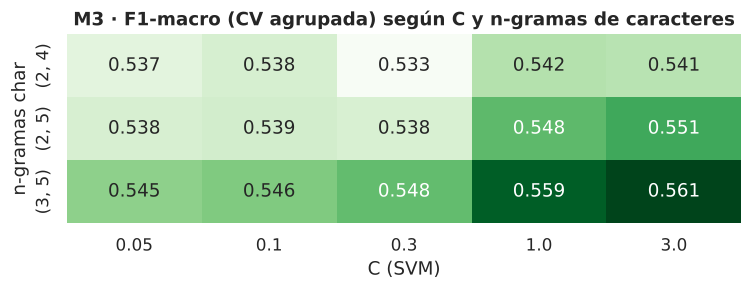

Bitácora de experimentos (experimentos.csv):


,experimento,modelo,hiperparametros,F1_macro_CV,F1_macro_val,acc_val,seg_entrenamiento
0,E0 clase mayoritaria,M0,{},0.0000,0.1132,0.3946,0.0
1,E1 malla baseline,M1,"{""clf__C"": 30, ""tfidf__ngram_range"": [1, 1]}",0.4539,0.5927,0.6212,0.0
2,E1 malla baseline,M1,"{""clf__C"": 10, ""tfidf__ngram_range"": [1, 1]}",0.4440,0.5999,0.6212,0.0
3,E1 malla baseline,M1,"{""clf__C"": 0.1, ""tfidf__ngram_range"": [1, 1]}",0.4394,0.5537,0.5737,0.0
4,E2 malla NB,M2,"{""clf__alpha"": 0.05}",0.5497,0.5546,0.6260,0.0
5,E3.1 caracteres sobre texto crudo,M3,"{""texto"": ""texto"", ""usar_meta"": false}",0.4999,0.6079,0.6466,0.6
6,"E3.2 + normalización (abreviaturas, ortografía)",M3,"{""texto"": ""texto_norm_sin_way"", ""usar_meta"": false}",0.4941,0.6120,0.6466,0.5
7,E3.3 + traducción wayuunaiki con glosario,M3,"{""texto"": ""texto_norm"", ""usar_meta"": false}",0.5002,0.6167,0.6466,0.5
8,E3.4 + rasgos estructurales,M3,"{""texto"": ""texto_norm"", ""usar_meta"": true}",0.5478,0.6660,0.6672,1.0
9,E3.5 malla C × rango n-gramas,M3,"{""clf__estimator__C"": 3.0, ""feats__caracteres__tf__ngram_range"": [3, 5]}",0.5610,0.6565,0.6545,0.0


In [9]:
gs3, res3 = buscar_malla("M3 ajuste fino", m3_propuesto,
                         {"clf__estimator__C": [0.05, 0.1, 0.3, 1.0, 3.0],
                          "feats__caracteres__tf__ngram_range": [(2, 4), (2, 5), (3, 5)]})
for _, r in res3.head(3).iterrows():
    m = clone(m3_propuesto()).set_params(**r.params).fit(Xtr, ytr)
    registrar("E3.5 malla C × rango n-gramas", m, r.params, r.mean_test_score, 0)
M3 = gs3.best_estimator_

piv = res3.assign(C=res3.params.map(lambda p: p["clf__estimator__C"]),
                  ngr=res3.params.map(lambda p: str(p["feats__caracteres__tf__ngram_range"]))).pivot(index="ngr", columns="C", values="mean_test_score")
fig, ax = plt.subplots(figsize=(7, 2.8))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Greens", ax=ax, cbar=False)
ax.set(title="M3 · F1-macro (CV agrupada) según C y n-gramas de caracteres", xlabel="C (SVM)", ylabel="n-gramas char")
plt.tight_layout(); plt.show()

bit = pd.DataFrame(bitacora)
bit.to_csv(OUT / "experimentos.csv", index=False)
print("Bitácora de experimentos (experimentos.csv):"); display(bit)

## 6. Evaluación comparativa
Cada modelo final (mejor configuración) se evalúa **una sola vez** en *test* (plantillas no vistas) y en el **test externo** (mensajes escritos a mano). Métricas:
- **F1-macro** (principal), **accuracy**, **accuracy balanceada**
- **Precisión / recall por clase** (en PQRS, un *recall* bajo en Reclamo significa reclamos que el sistema no tramita como tales)
- **AUC ROC macro (one-vs-rest)** a partir de las probabilidades

F1_macro                accuracy                AUC_macro_ovr               
conjunto                       val   test externo      val   test externo           val   test externo
modelo                                                                                                
M0 Mayoritaria               0.113  0.102   0.087    0.395  0.342   0.279         0.500  0.500   0.500
M1 Baseline TF-IDF+LogReg    0.593  0.830   0.659    0.621  0.804   0.632         0.826  0.953   0.807
M2 TF-IDF+ComplementNB       0.555  0.854   0.521    0.626  0.806   0.515         0.875  0.958   0.755
M3 Propuesto                 0.657  0.851   0.536    0.655  0.791   0.559         0.930  0.955   0.880

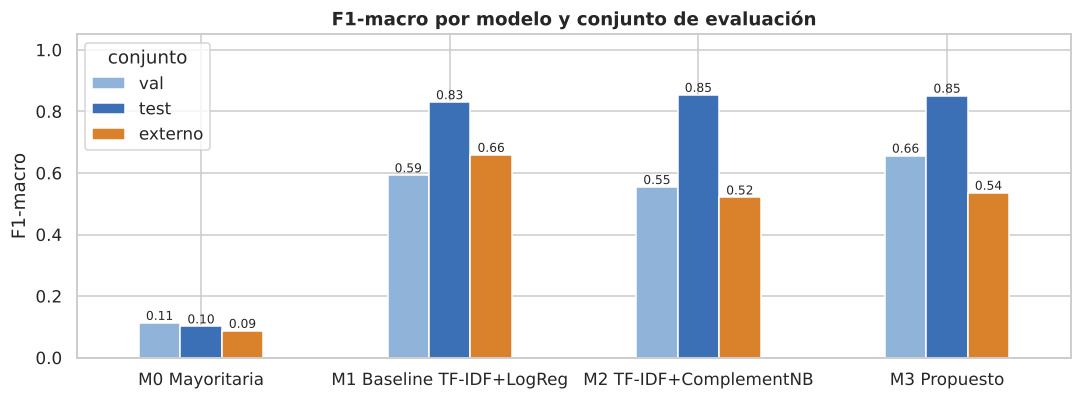

In [10]:
MODELOS = {"M0 Mayoritaria": m0, "M1 Baseline TF-IDF+LogReg": M1, "M2 TF-IDF+ComplementNB": M2, "M3 Propuesto": M3}

def evaluar(modelo, D):
    y, p = D.tipo_pqrs, modelo.predict(D)
    fila = {"F1_macro": f1_score(y, p, average="macro"), "accuracy": accuracy_score(y, p),
            "acc_balanceada": balanced_accuracy_score(y, p)}
    try:
        proba = modelo.predict_proba(D)
        fila["AUC_macro_ovr"] = roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=modelo.classes_)
    except Exception:
        fila["AUC_macro_ovr"] = np.nan
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=CLASES, zero_division=0)
    for c, a, b in zip(CLASES, pr, rc):
        fila[f"P_{c}"], fila[f"R_{c}"] = a, b
    return fila

resultados = []
for nombre, m in MODELOS.items():
    for conj, D in [("val", val), ("test", test), ("externo", ext)]:
        resultados.append({"modelo": nombre, "conjunto": conj, **evaluar(m, D)})
res = pd.DataFrame(resultados)
tabla = res.pivot(index="modelo", columns="conjunto", values=["F1_macro", "accuracy", "AUC_macro_ovr"]).round(3)
tabla = tabla.reindex(columns=["val", "test", "externo"], level=1)
display(tabla)
res.round(4).to_csv(OUT / "resultados_modelos.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
plot = res.pivot(index="modelo", columns="conjunto", values="F1_macro")[["val", "test", "externo"]]
plot.plot.bar(ax=ax, rot=0, color=["#8fb3d9", "#3b6fb6", "#d9822b"])
ax.set(title="F1-macro por modelo y conjunto de evaluación", ylabel="F1-macro", xlabel=""); ax.set_ylim(0, 1.05)
for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=8)
ax.legend(title="conjunto", loc="upper left"); plt.tight_layout(); plt.show()

Precisión (P) y recall (R) por clase en TEST:


,P_Peticion,R_Peticion,P_Queja,R_Queja,P_Reclamo,R_Reclamo,P_Sugerencia,R_Sugerencia,P_Otro,R_Otro
modelo,,,,,,,,,,
M0 Mayoritaria,0.34,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
M1 Baseline TF-IDF+LogReg,0.89,0.86,0.86,0.63,0.67,0.86,0.97,0.92,0.81,0.91
M2 TF-IDF+ComplementNB,0.82,0.77,0.82,0.94,0.71,0.68,0.95,1.00,1.00,0.88
M3 Propuesto,0.82,0.78,0.93,0.80,0.61,0.74,1.00,0.94,1.00,0.91


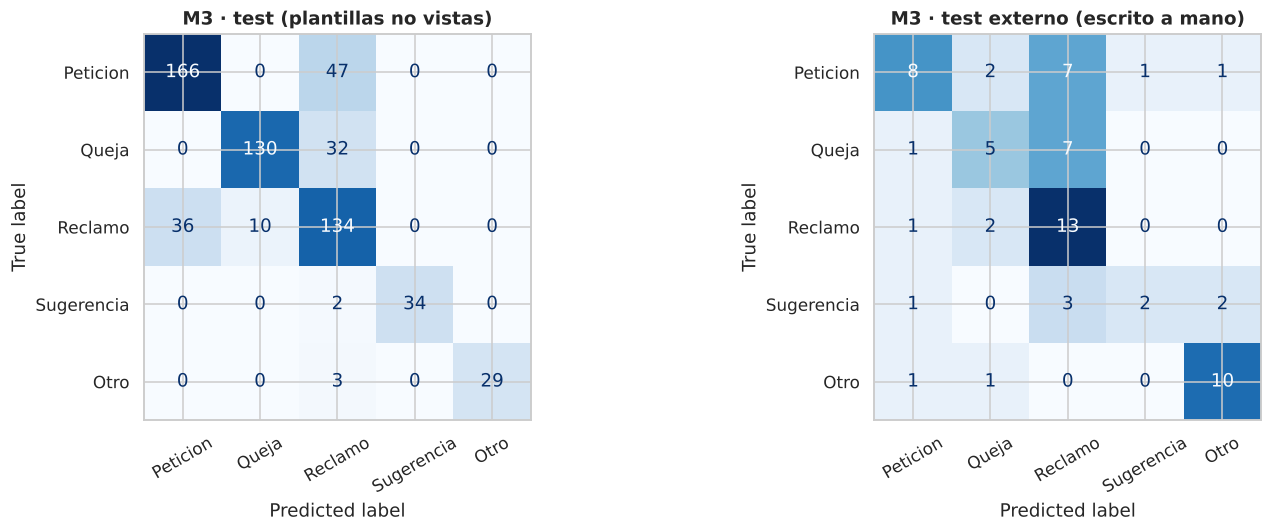

              precision    recall  f1-score   support

    Peticion      0.667     0.421     0.516        19
       Queja      0.500     0.385     0.435        13
     Reclamo      0.433     0.812     0.565        16
  Sugerencia      0.667     0.250     0.364         8
        Otro      0.769     0.833     0.800        12

    accuracy                          0.559        68
   macro avg      0.607     0.540     0.536        68
weighted avg      0.598     0.559     0.544        68



In [11]:
print("Precisión (P) y recall (R) por clase en TEST:")
pr_tab = res[res.conjunto == "test"].set_index("modelo")[[f"{m}_{c}" for c in CLASES for m in ("P", "R")]].round(2)
display(pr_tab)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (titulo, D) in zip(axes, [("M3 · test (plantillas no vistas)", test), ("M3 · test externo (escrito a mano)", ext)]):
    ConfusionMatrixDisplay(confusion_matrix(D.tipo_pqrs, M3.predict(D), labels=CLASES), display_labels=CLASES).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(titulo); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print(classification_report(ext.tipo_pqrs, M3.predict(ext), labels=CLASES, digits=3, zero_division=0))

### Análisis de errores (test externo)

In [12]:
ext["pred_M1"] = M1.predict(ext); ext["pred_M3"] = M3.predict(ext)
ext["conf_M3"] = M3.predict_proba(ext).max(axis=1)
errores = ext[ext.pred_M3 != ext.tipo_pqrs][["texto", "tipo_pqrs", "pred_M3", "conf_M3", "pred_M1"]].sort_values("conf_M3", ascending=False)
print(f"Errores de M3 en el test externo: {len(errores)} de {len(ext)}")
display(errores.round(2))
print("Aciertos de M3 que M1 falló:")
display(ext[(ext.pred_M3 == ext.tipo_pqrs) & (ext.pred_M1 != ext.tipo_pqrs)][["texto", "tipo_pqrs", "pred_M1"]].head(10))

Errores de M3 en el test externo: 30 de 68


,texto,tipo_pqrs,pred_M3,conf_M3,pred_M1
43,Solicito el reembolso del valor cobrado indebidamente por el examen de laboratorio.,Reclamo,Peticion,0.98,Peticion
28,"el centro de salud se esta cayendo, el techo gotea",Queja,Reclamo,0.94,Reclamo
5,me mandaron una resonancia y no se donde la autorizan,Peticion,Reclamo,0.93,Reclamo
17,ya respondieron lo que puse la otra vez?,Peticion,Reclamo,0.92,Reclamo
16,radique un derecho de peticion el mes pasado y no se nada,Peticion,Reclamo,0.92,Reclamo
48,podrian dar las fichas por whatsapp para no madrugar,Sugerencia,Reclamo,0.91,Reclamo
0,"buenas tardes, quisiera agendar control de crecimiento y desarrollo para mi niña de 2 ...",Peticion,Reclamo,0.89,Peticion
66,cual es el numero de la registraduria,Otro,Peticion,0.86,Peticion
24,desde las 5 de la mañana en la fila y todavia nada,Queja,Reclamo,0.86,Queja
37,el especialista no vino y nadie aviso,Reclamo,Queja,0.85,Queja


Aciertos de M3 que M1 falló:


,texto,tipo_pqrs,pred_M1
8,nesesito q me aprueben la orden del esamen,Peticion,Reclamo
39,tenia la cirugia programada para hoy y la suspendieron,Reclamo,Peticion
46,le negaron la remision a riohacha a mi hijo,Reclamo,Peticion
57,buen dia,Otro,Queja
67,hay partido hoy?,Otro,Queja


### Clasificación de la intención fina (17 clases)
El bot necesita también la intención (p. ej. `medicamento_no_entregado`) para dar la respuesta correcta. Se reutiliza la arquitectura de M1 y M3 con la etiqueta `intencion`.

In [13]:
yi = train.intencion
res_int = []
for nombre, ctor in [("M1 Baseline", lambda: clone(M1)), ("M3 Propuesto", lambda: clone(M3))]:
    m = ctor().fit(train, yi)
    for conj, D in [("val", val), ("test", test), ("externo", ext)]:
        p = m.predict(D)
        res_int.append({"modelo": nombre, "conjunto": conj, "F1_macro": f1_score(D.intencion, p, average="macro"),
                        "accuracy": accuracy_score(D.intencion, p)})
    if nombre.startswith("M3"): M3_int = m
display(pd.DataFrame(res_int).pivot(index="modelo", columns="conjunto", values=["F1_macro", "accuracy"]).round(3)
        .reindex(columns=["val", "test", "externo"], level=1))

F1_macro                accuracy               
conjunto          val   test externo      val   test externo
modelo                                                      
M1 Baseline     0.280  0.347   0.412    0.345  0.332   0.426
M3 Propuesto    0.343  0.285   0.438    0.409  0.302   0.456

### Robustez: 10 particiones agrupadas distintas
Con pocas plantillas por intención, **una sola partición es ruidosa**: el F1 cambia mucho según qué plantilla cae en test. Para comparar los modelos con más rigor se repite el experimento con 10 semillas: en cada una se aparta 1 plantilla por intención como test, se entrena con el resto (train+val) con los hiperparámetros ya elegidos, y se evalúa en ese test y en el test externo.

F1-macro en 10 particiones (media ± desviación):


test (plantillas no vistas)        test externo       
                                       mean    std         mean    std
modelo                                                                
M1 Baseline                           0.632  0.093        0.665  0.036
M2 ComplementNB                       0.660  0.116        0.569  0.049
M3 Propuesto                          0.677  0.095        0.675  0.030

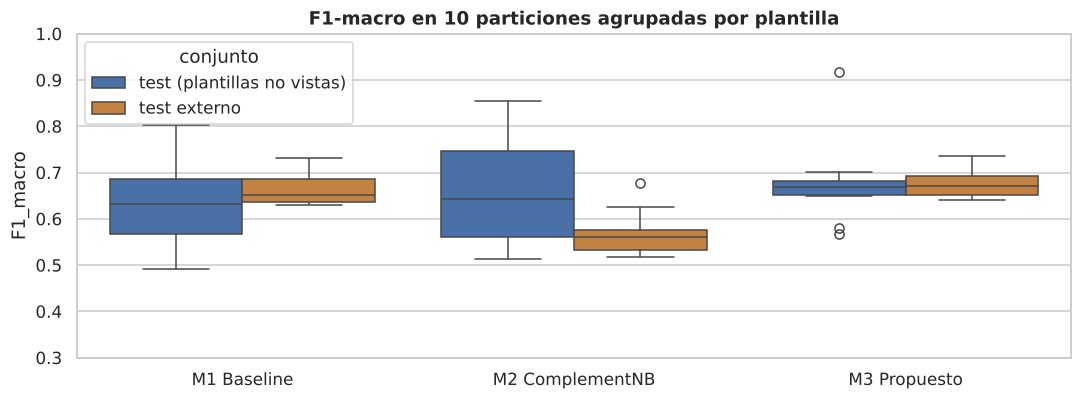

In [14]:
filas = []
for seed in range(10):
    r = np.random.RandomState(seed); asg = {}
    for intent, g in d.groupby("intencion"):
        pl = sorted(g.plantilla_id.unique()); r.shuffle(pl)
        for i, p_ in enumerate(pl): asg[p_] = "test" if i == 0 else "trainval"
    tv_, te_ = d[d.plantilla_id.map(asg) == "trainval"], d[d.plantilla_id.map(asg) == "test"]
    for nombre, base in [("M1 Baseline", M1), ("M2 ComplementNB", M2), ("M3 Propuesto", M3)]:
        m = clone(base).fit(tv_, tv_.tipo_pqrs)
        filas.append({"semilla": seed, "modelo": nombre,
                      "test (plantillas no vistas)": f1_score(te_.tipo_pqrs, m.predict(te_), average="macro"),
                      "test externo": f1_score(ext.tipo_pqrs, m.predict(ext), average="macro")})
rob = pd.DataFrame(filas)
resumen_rob = rob.groupby("modelo")[["test (plantillas no vistas)", "test externo"]].agg(["mean", "std"]).round(3)
print("F1-macro en 10 particiones (media ± desviación):"); display(resumen_rob)
rob.to_csv(OUT / "robustez_10_particiones.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.boxplot(data=rob.melt(id_vars=["semilla", "modelo"], var_name="conjunto", value_name="F1_macro"),
            x="modelo", y="F1_macro", hue="conjunto", ax=ax, palette=["#3b6fb6", "#d9822b"])
ax.set(title="F1-macro en 10 particiones agrupadas por plantilla", xlabel="", ylim=(0.3, 1)); plt.tight_layout(); plt.show()

## 7. Umbral de confianza y regla de respaldo (R2)
En un servicio de salud, **es preferible preguntar que equivocarse**. Se elige el umbral τ en *validación* y se reporta en *test* y *externo*: cobertura (mensajes que el modelo decide solo) vs. exactitud de esas decisiones.

τ elegido en validación (menor τ con accuracy ≥ 90% en lo decidido): 0.8
  val      cobertura=42.8%  accuracy en lo decidido=91.5%  (el 57.2% restante → el bot pregunta)
  test     cobertura=36.0%  accuracy en lo decidido=92.0%  (el 64.0% restante → el bot pregunta)
  externo  cobertura=55.9%  accuracy en lo decidido=73.7%  (el 44.1% restante → el bot pregunta)


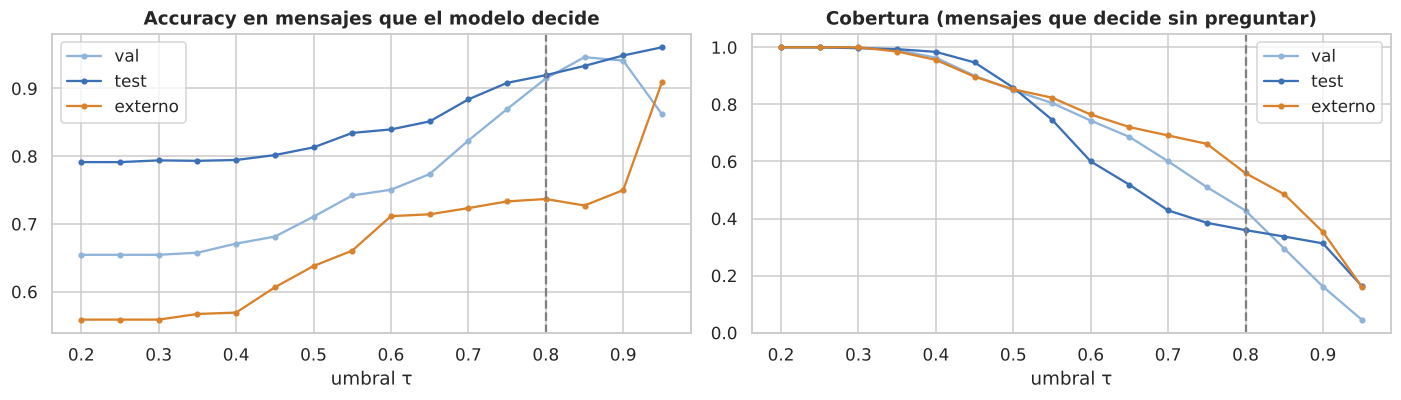

In [15]:
def curva(m, D, taus):
    pr = m.predict_proba(D); conf = pr.max(1); pred = m.classes_[pr.argmax(1)]
    ok = pred == D.tipo_pqrs.values
    return pd.DataFrame([{"tau": t, "cobertura": (conf >= t).mean(),
                          "accuracy_decididos": ok[conf >= t].mean() if (conf >= t).any() else np.nan} for t in taus])
taus = np.round(np.arange(0.2, 0.96, 0.05), 2)
cv_val, cv_test, cv_ext = (curva(M3, D, taus) for D in (val, test, ext))
OBJ = 0.90
cand = cv_val[cv_val.accuracy_decididos >= OBJ]
TAU = float(cand.tau.iloc[0]) if len(cand) else 0.6
print(f"τ elegido en validación (menor τ con accuracy ≥ {OBJ:.0%} en lo decidido): {TAU}")
fila = lambda c: c.loc[c.tau == TAU].iloc[0]
for n, c in [("val", cv_val), ("test", cv_test), ("externo", cv_ext)]:
    print(f"  {n:8s} cobertura={fila(c).cobertura:.1%}  accuracy en lo decidido={fila(c).accuracy_decididos:.1%}  "
          f"(el {1-fila(c).cobertura:.1%} restante → el bot pregunta)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for n, c, col in [("val", cv_val, "#8fb3d9"), ("test", cv_test, "#3b6fb6"), ("externo", cv_ext, "#d9822b")]:
    axes[0].plot(c.tau, c.accuracy_decididos, marker="o", ms=3, label=n, color=col)
    axes[1].plot(c.tau, c.cobertura, marker="o", ms=3, label=n, color=col)
for ax, t in zip(axes, ["Accuracy en mensajes que el modelo decide", "Cobertura (mensajes que decide sin preguntar)"]):
    ax.axvline(TAU, ls="--", color="gray"); ax.set(title=t, xlabel="umbral τ"); ax.legend()
plt.tight_layout(); plt.show()

### Pipeline completo del bot (reglas + modelo) y guardado

In [16]:
RESPUESTA_R0 = "No entendí tu mensaje. ¿Me cuentas qué necesitas? Puedes escribir o enviar una nota de voz."
RESPUESTA_R1 = "⚠️ Esto puede ser una urgencia. Llama ya al 123 o acude al servicio de urgencias más cercano."
RESPUESTA_R2 = "¿Tu mensaje es para: 1️⃣ pedir algo, 2️⃣ poner una queja, 3️⃣ un reclamo o 4️⃣ dar una sugerencia?"

def clasificar(texto):
    norm = normalizar(texto)
    if not norm.strip():
        return {"accion": "R0_reformular", "respuesta": RESPUESTA_R0}
    if regla_alerta(norm):
        return {"accion": "R1_urgencia", "respuesta": RESPUESTA_R1}
    fila = preparar(pd.DataFrame({"texto": [texto]}))
    fila["texto_norm_sin_way"] = fila.texto.map(lambda s: normalizar(s, traducir_way=False))
    p = M3.predict_proba(fila)[0]
    tipo, conf = M3.classes_[p.argmax()], float(p.max())
    if conf < TAU:
        return {"accion": "R2_preguntar", "respuesta": RESPUESTA_R2, "tipo_probable": tipo, "confianza": round(conf, 2)}
    return {"accion": "clasificado", "tipo_pqrs": tipo, "intencion": M3_int.predict(fila)[0], "confianza": round(conf, 2)}

for t in ["jamaya, mi hijo ayuulii con tuttaa y no hay tottoolu en el puesto", "👍", "mi bebe convulsiona",
          "no me han dado la insulina", "podrian poner un medico los domingos", "hola", "lo de la otra vez"]:
    print(f"{t!r:65} → {clasificar(t)}")

# Modelo de despliegue: misma configuración, reentrenado con TODOS los datos etiquetados (train + val + test)
M3_final = clone(M3).fit(d, d.tipo_pqrs)
M3_int_final = clone(M3).fit(d, d.intencion)
joblib.dump({"tipo": M3_final, "intencion": M3_int_final, "tau": TAU, "way2esp": WAY2ESP}, MODELS_DIR / "modelo_pqrs_m3.joblib")
print("\nModelo de despliegue (reentrenado con todos los datos) guardado en modelo_pqrs_m3.joblib")

'jamaya, mi hijo ayuulii con tuttaa y no hay tottoolu en el puesto' → {'accion': 'clasificado', 'tipo_pqrs': 'Queja', 'intencion': 'mal_trato', 'confianza': 0.95}
'👍'                                                               → {'accion': 'R0_reformular', 'respuesta': 'No entendí tu mensaje. ¿Me cuentas qué necesitas? Puedes escribir o enviar una nota de voz.'}
'mi bebe convulsiona'                                             → {'accion': 'R1_urgencia', 'respuesta': '⚠️ Esto puede ser una urgencia. Llama ya al 123 o acude al servicio de urgencias más cercano.'}
'no me han dado la insulina'                                      → {'accion': 'clasificado', 'tipo_pqrs': 'Reclamo', 'intencion': 'medicamento_no_entregado', 'confianza': 0.9}
'podrian poner un medico los domingos'                            → {'accion': 'R2_preguntar', 'respuesta': '¿Tu mensaje es para: 1️⃣ pedir algo, 2️⃣ poner una queja, 3️⃣ un reclamo o 4️⃣ dar una sugerencia?', 'tipo_probable': 'Sugerencia', 'confianza'


Modelo de despliegue (reentrenado con todos los datos) guardado en modelo_pqrs_m3.joblib


## 8. Modelo transformer: BETO (BERT en español) — ejecutar en Colab

**Por qué:** BETO (`dccuchile/bert-base-spanish-wwm-cased`) fue preentrenado con mucho texto en español, así que reconoce sinónimos y paráfrasis que no comparten palabras con el entrenamiento (p. ej. *"me humilló"* ≈ maltrato). Es el modelo nombrado en la propuesta.

**Cómo ejecutar:** en Colab → *Entorno de ejecución → Cambiar tipo → GPU T4*, poner `RUN_BERT = True` y ejecutar. Usa **las mismas particiones** y el texto normalizado, así que sus métricas son directamente comparables con la tabla de la sección 6. (≈ 5 min en T4.)

In [17]:
RUN_BERT = False   # ← cambiar a True en Colab con GPU

if RUN_BERT:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "datasets", "accelerate"])
    import torch
    from datasets import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                              DataCollatorWithPadding, EarlyStoppingCallback)

    MODEL = "dccuchile/bert-base-spanish-wwm-cased"
    lab2id = {c: i for i, c in enumerate(CLASES)}; id2lab = {i: c for c, i in lab2id.items()}
    tok = AutoTokenizer.from_pretrained(MODEL)
    def a_ds(D):
        ds = Dataset.from_dict({"text": D.texto_norm.tolist(), "label": D.tipo_pqrs.map(lab2id).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=96), batched=True)
    ds_tr, ds_va, ds_te, ds_ex = map(a_ds, (train, val, test, ext))

    # pesos de clase en la pérdida (desbalance)
    pesos = torch.tensor((len(train) / (len(CLASES) * train.tipo_pqrs.value_counts().reindex(CLASES))).values, dtype=torch.float)
    class TrainerPonderado(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kw):
            labels = inputs.pop("labels"); out = model(**inputs)
            loss = torch.nn.functional.cross_entropy(out.logits, labels, weight=pesos.to(out.logits.device))
            return (loss, out) if return_outputs else loss
    def metricas(ev):
        pred = ev.predictions.argmax(-1)
        return {"f1_macro": f1_score(ev.label_ids, pred, average="macro"), "accuracy": accuracy_score(ev.label_ids, pred)}

    resultados_bert = []
    for lr in [2e-5, 5e-5]:                        # ajuste de hiperparámetros: tasa de aprendizaje
        model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=len(CLASES), id2label=id2lab, label2id=lab2id)
        args = TrainingArguments(output_dir=f"beto_lr{lr}", learning_rate=lr, num_train_epochs=6, per_device_train_batch_size=32,
                                 per_device_eval_batch_size=64, weight_decay=0.01, warmup_ratio=0.1, eval_strategy="epoch",
                                 save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1_macro",
                                 save_total_limit=1, seed=SEED, report_to="none", fp16=torch.cuda.is_available())
        tr = TrainerPonderado(model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_va, compute_metrics=metricas,
                              data_collator=DataCollatorWithPadding(tok), callbacks=[EarlyStoppingCallback(2)])
        tr.train()
        for conj, ds in [("val", ds_va), ("test", ds_te), ("externo", ds_ex)]:
            m = tr.evaluate(ds)
            resultados_bert.append({"modelo": f"M4 BETO lr={lr}", "conjunto": conj,
                                    "F1_macro": m["eval_f1_macro"], "accuracy": m["eval_accuracy"]})
    rb = pd.DataFrame(resultados_bert)
    display(rb.pivot(index="modelo", columns="conjunto", values=["F1_macro", "accuracy"]).round(3))
    display(pd.concat([res[["modelo", "conjunto", "F1_macro", "accuracy"]], rb])
              .pivot(index="modelo", columns="conjunto", values="F1_macro").round(3)[["val", "test", "externo"]])
else:
    print("BETO no se ejecutó en este entorno (sin GPU ni acceso a Hugging Face). Ejecutar en Colab con RUN_BERT = True.")

BETO no se ejecutó en este entorno (sin GPU ni acceso a Hugging Face). Ejecutar en Colab con RUN_BERT = True.


## 9. Conclusiones de la Fase 2 y siguiente iteración

**Resultados principales (tipo de PQRS, F1-macro):**

In [18]:
final = pd.DataFrame({
    "F1 val": res[res.conjunto == "val"].set_index("modelo").F1_macro,
    "AUC val": res[res.conjunto == "val"].set_index("modelo").AUC_macro_ovr,
})
rm = rob.groupby("modelo")[["test (plantillas no vistas)", "test externo"]].agg(["mean", "std"])
mapa = {"M1 Baseline": "M1 Baseline TF-IDF+LogReg", "M2 ComplementNB": "M2 TF-IDF+ComplementNB", "M3 Propuesto": "M3 Propuesto"}
final["F1 test (10 particiones)"] = [f"{rm.loc[k, ('test (plantillas no vistas)','mean')]:.3f} ± {rm.loc[k, ('test (plantillas no vistas)','std')]:.3f}" if k else "—"
                                     for k in [next((a for a, b in mapa.items() if b == m), None) for m in final.index]]
final["F1 externo (10 particiones)"] = [f"{rm.loc[k, ('test externo','mean')]:.3f} ± {rm.loc[k, ('test externo','std')]:.3f}" if k else "—"
                                        for k in [next((a for a, b in mapa.items() if b == m), None) for m in final.index]]
display(final.round(3))

,F1 val,AUC val,F1 test (10 particiones),F1 externo (10 particiones)
modelo,,,,
M0 Mayoritaria,0.113,0.500,—,—
M1 Baseline TF-IDF+LogReg,0.593,0.826,0.632 ± 0.093,0.665 ± 0.036
M2 TF-IDF+ComplementNB,0.555,0.875,0.660 ± 0.116,0.569 ± 0.049
M3 Propuesto,0.657,0.930,0.677 ± 0.095,0.675 ± 0.030


**Lectura:**
1. **Todos los modelos superan con claridad al piso** (M0, F1 ≈ 0,1). El problema es aprendible.
2. **M3 (propuesto) es el mejor en validación** (F1 y sobre todo AUC, lo que indica probabilidades más útiles para el umbral de seguridad) y el **mejor en promedio** en las 10 particiones, tanto en plantillas no vistas como en el test externo. La ventaja sobre el baseline es **moderada** y está dentro de la variación entre particiones: no hay que sobrevender la mejora.
3. **Lo que más aportó en la iteración de M3** fueron los **rasgos estructurales** (longitud, mayúsculas, pregunta, emojis, wayuunaiki) y los **n-gramas de caracteres**; la normalización ortográfica y el glosario wayuu aportan poco en el F1 global porque afectan a pocos mensajes, pero son los que permiten entender mensajes como *"KIERO SITA PAL DOTOR"* o *"tottoolu"*.
4. **La regla de respaldo R2 hace seguro el sistema, pero hoy pregunta demasiado:** con τ = 0,8 (elegido en validación), lo que el bot decide solo tiene ~92 % de exactitud en test, pero decide solo en ~36 % de los mensajes; el resto lo resuelve preguntando con botones. En el test externo decide más (~56 %) pero acierta menos (~74 %): las probabilidades están **sobreconfiadas ante formulaciones nuevas**. Mejorar los datos debería subir la cobertura sin bajar la exactitud.
5. **La intención fina (17 clases) aún no es usable** (F1 ≈ 0,3–0,45): con 1–3 plantillas por intención en entrenamiento, el modelo no generaliza a formulaciones nuevas.
6. **Cuello de botella: los datos, no el algoritmo.** El dataset sintético tiene poca variedad (≈ 70 plantillas). Los errores del test externo son paráfrasis legítimas (*"se burlaron de mi abuela"*, *"ojalá abrieran los sábados"*) que no comparten palabras con las plantillas — justo lo que un modelo preentrenado como BETO debería resolver mejor.

**Siguiente iteración:**
- Ejecutar **BETO** (sección 8) en Colab con GPU y añadirlo a la comparación.
- **Ampliar la diversidad del dataset**: más plantillas y paráfrasis por intención, idealmente redactadas por personal de atención al usuario y por hablantes wayuu; para la intención fina, ≥ 10 formulaciones distintas por intención.
- Conseguir un **test externo escrito por otras personas** (el actual lo redactó el mismo equipo que diseñó las plantillas).
- Para la intención fina, evaluar un enfoque **jerárquico** (primero tipo PQRS, luego intención dentro del tipo).